In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
import random

In [56]:
repo_root='/Users/evanlin/2026-summar-ai/'
file_path = repo_root + 'sections/s02/homework/openpoly_calculated_properties.csv'
df = pd.read_csv(file_path)

In [57]:
seed = 42
random.seed(seed)
np.random.seed(seed)

In [58]:
failed_energy_calculation = (df['Energy_Hatree'] == 0).sum()
failed_energy_calculation

np.int64(74)

# Define and audit the modeling table


In [59]:
cleaned_df = df[df['Energy_Hatree'] != 0].drop(columns=['Name', 'reactant_1', 'reactant_2', 'psmiles', 'SMILES', 'reaction_type', 'Software', 'Theory_Level', 'Source'])

print("Original number of molecules: ", len(df))
print("Number of molecules after cleaning: ", len(cleaned_df))
print("False energy calculations removed: ", len(df) - len(cleaned_df))

Original number of molecules:  1000
Number of molecules after cleaning:  926
False energy calculations removed:  74


In [60]:
(cleaned_df.select_dtypes(include=["number"]) == 0).sum()

id                                                0
Energy_Hatree                                     0
es                                                0
Isotropic_Polarizability_au                       0
HOMO_eV                                           0
LUMO_eV                                           0
Inner_energy_correction_Hatree                    0
Thermal_correction_to_Enthalpy_Hatree             0
Thermal_correction_to_Gibbs_Free_Energy_Hatree    0
Entropy_Hatree                                    0
Dipole_Debye                                      0
Gibbs_Free_Energy_Hatree                          0
Enthalpy_Hatree                                   0
HOMO_LUMO_Gap_eV                                  0
dtype: int64

In [61]:
indices = cleaned_df.index

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=seed
)

train_df = cleaned_df.loc[train_idx]
test_df = cleaned_df.loc[test_idx]

In [62]:
gap_threshold = train_df["HOMO_LUMO_Gap_eV"].median()

print(gap_threshold)

8.33225


In [63]:
train_df

,id,Energy_Hatree,es,Isotropic_Polarizability_au,HOMO_eV,LUMO_eV,Inner_energy_correction_Hatree,Thermal_correction_to_Enthalpy_Hatree,Thermal_correction_to_Gibbs_Free_Energy_Hatree,Entropy_Hatree,Dipole_Debye,Gibbs_Free_Energy_Hatree,Enthalpy_Hatree,HOMO_LUMO_Gap_eV
241,242,-4077.707023,0.998299,259.21871,-8.2759,-0.4092,0.268049,0.000944,0.195672,0.073321,3.443721,-4077.511351,-4077.438030,7.8667
747,748,-4512.592808,0.952353,325.56736,-8.5007,-0.0912,0.427172,0.000944,0.335322,0.092794,3.781331,-4512.257487,-4512.164692,8.4095
634,635,-3736.029205,0.998617,272.44516,-8.3576,0.1618,0.365047,0.000944,0.285995,0.079996,5.632144,-3735.743210,-3735.663214,8.5194
956,957,-1677.986904,0.999252,270.69900,-8.2445,0.1521,0.329027,0.000944,0.252169,0.077802,6.161401,-1677.734734,-1677.656932,8.3966
496,497,-1464.487651,0.996100,293.26548,-8.2946,-0.1234,0.403988,0.000944,0.321042,0.083891,8.297962,-1464.166609,-1464.082719,8.1712
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113,114,-1411.414562,0.990102,235.25380,-8.4364,0.1597,0.371516,0.000944,0.290756,0.081704,4.180714,-1411.123806,-1411.042101,8.5961
287,288,-2069.670952,0.930158,320.04579,-8.3796,-0.5277,0.458556,0.000944,0.361561,0.097939,5.600926,-2069.309391,-2069.211452,7.8519
928,929,-1120.156310,0.998762,204.53946,-8.3697,0.2343,0.306119,0.000944,0.235494,0.071569,4.145289,-1119.920816,-1119.849247,8.6040
467,468,-2284.003552,0.990292,328.96052,-8.6767,-0.5883,0.376460,0.000944,0.291028,0.086376,6.523618,-2283.712524,-2283.626148,8.0884


In [64]:
train_df['high_gap'] = (train_df['HOMO_LUMO_Gap_eV'] >= gap_threshold).astype(int)
train_gap_df = train_df['high_gap']

In [65]:
train_df['high_gap'].value_counts(0)

high_gap
0    370
1    370
Name: count, dtype: int64

In [66]:
print('Gap Threshold:', gap_threshold)
print('High Gap Count:', train_df['high_gap'].sum())
print('Low Gap Count:', (1 - train_df['high_gap']).sum())

Gap Threshold: 8.33225
High Gap Count: 370
Low Gap Count: 370


In [67]:
#Define and information
print('Prediction target: HOMO_LUMO_GAP')
print('Unit and unit of observation: eV')
print("Task meaning: The regression task predicts the continuous HOMO-LUMO gap value for each polymer. The classification task predicts whether the polymer belongs to the high-gap or low-gap group based on the training median threshold.")

print("Raw rows:", len(df))
print("Valid rows:", len(cleaned_df))
set(train_idx).intersection(set(test_idx))

Prediction target: HOMO_LUMO_GAP
Unit and unit of observation: eV
Task meaning: The regression task predicts the continuous HOMO-LUMO gap value for each polymer. The classification task predicts whether the polymer belongs to the high-gap or low-gap group based on the training median threshold.
Raw rows: 1000
Valid rows: 926


set()

In [68]:
train_predictors_df = train_df.drop(columns=['HOMO_LUMO_Gap_eV', 'HOMO_eV', 'id', 'LUMO_eV'])
test_predictors_df = test_df.drop(columns=['HOMO_LUMO_Gap_eV', 'HOMO_eV', 'id', 'LUMO_eV'])
train_target_df = train_df['HOMO_LUMO_Gap_eV']
test_target_df = test_df['HOMO_LUMO_Gap_eV']

In [69]:
test_predictors_df

,Energy_Hatree,es,Isotropic_Polarizability_au,Inner_energy_correction_Hatree,Thermal_correction_to_Enthalpy_Hatree,Thermal_correction_to_Gibbs_Free_Energy_Hatree,Entropy_Hatree,Dipole_Debye,Gibbs_Free_Energy_Hatree,Enthalpy_Hatree
346,-1354.575596,0.999265,287.99745,0.445339,0.000944,0.362369,0.083915,7.547149,-1354.213227,-1354.129312
648,-4002.060335,0.983311,310.28316,0.420866,0.000944,0.335383,0.086428,4.913498,-4001.724952,-4001.638525
34,-2088.794687,0.997851,276.48166,0.323673,0.000944,0.242296,0.082320,5.411825,-2088.552391,-2088.470070
890,-1946.843189,0.993704,349.48183,0.551366,0.000944,0.460576,0.091734,11.284560,-1946.382613,-1946.290878
314,-1366.997491,0.998837,282.52483,0.363094,0.000944,0.284887,0.079152,2.983780,-1366.712604,-1366.633453
...,...,...,...,...,...,...,...,...,...,...
896,-2566.662609,0.738763,328.96356,0.524800,0.000944,0.426566,0.099178,10.371874,-2566.236043,-2566.136865
971,-4074.700991,0.995309,351.23629,0.362738,0.000944,0.277542,0.086140,8.644121,-4074.423448,-4074.337309
670,-1139.568677,0.997739,218.14079,0.347271,0.000944,0.272612,0.075603,6.617391,-1139.296065,-1139.220462
912,-1172.687329,0.994552,223.05428,0.331969,0.000944,0.258090,0.074824,5.263864,-1172.429240,-1172.354416


HOMO_LUMO_GAP is the target and hence cannot not be used as prediction.

HOMO and LUMO are connected with HOMO_LUMO_GAP by the equation GAP = LUMO - HOMO, therefore also has to be removed. 

id is ordered and might cause false trends and relationships

count    740.000000
mean       8.307277
std        0.470673
min        6.512300
25%        8.006775
50%        8.332250
75%        8.593650
max       10.001000
Name: HOMO_LUMO_Gap_eV, dtype: float64


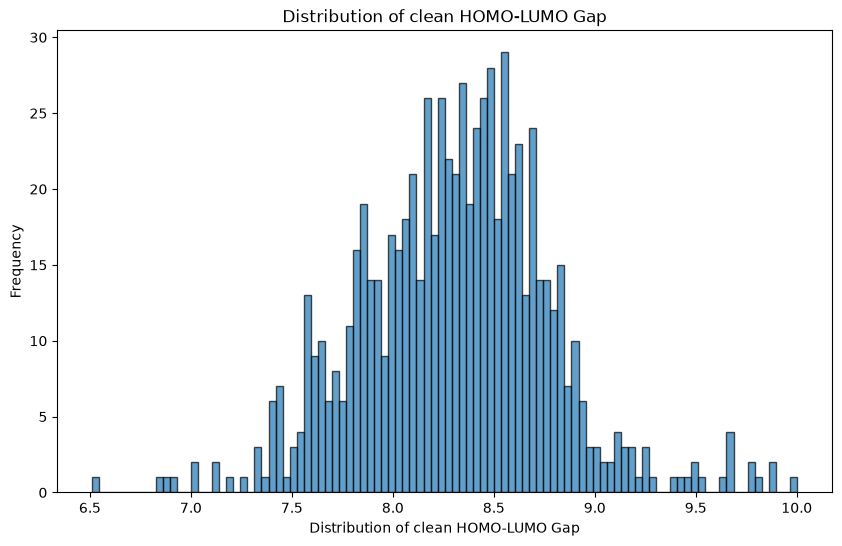

/var/folders/fv/9zptgcbd3591y8n1d18yqnlw0000gn/T/ipykernel_91638/227773986.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(target_df, vert=False)


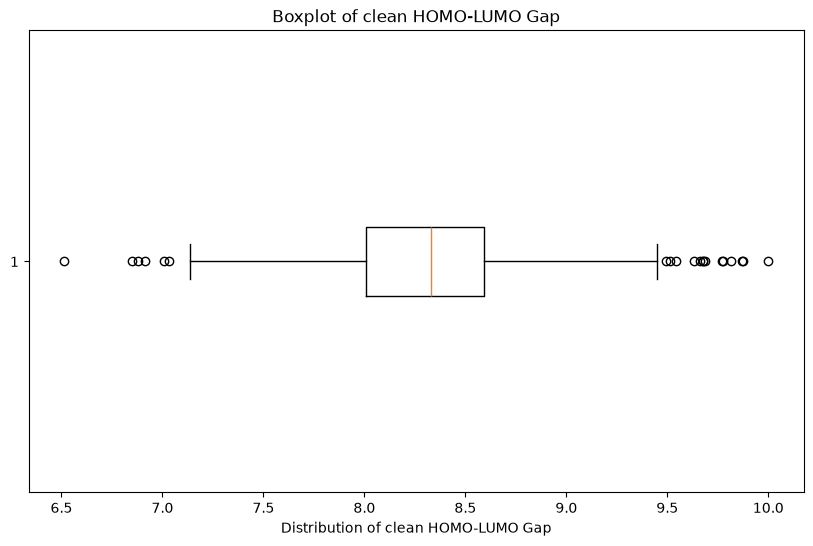

In [70]:
# Trained Gaps distribution and box plot
target_df = train_df['HOMO_LUMO_Gap_eV']
print(target_df.describe())
plt.figure(figsize=(10, 6))
plt.title('Distribution of clean HOMO-LUMO Gap')
plt.hist(target_df, alpha=0.7, bins=100, edgecolor='black')
plt.xlabel('Distribution of clean HOMO-LUMO Gap')
plt.ylabel('Frequency')
plt.show()

plt.figure(figsize=(10, 6))
plt.title('Boxplot of clean HOMO-LUMO Gap')
plt.boxplot(target_df, vert=False)
plt.xlabel('Distribution of clean HOMO-LUMO Gap')
plt.show()

In [71]:
predictors_df = train_df.drop(columns=['HOMO_LUMO_Gap_eV', 'HOMO_eV', 'id', 'LUMO_eV'])
number_predictors_df = predictors_df.select_dtypes(include='number')
predictors_table = pd.DataFrame({
    "dtype": number_predictors_df.dtypes,
    "missing": number_predictors_df.isna().sum(),
    "min": number_predictors_df.min(),
    "max": number_predictors_df.max(),
    "range": number_predictors_df.max() - number_predictors_df.min()
})
predictors_table


,dtype,missing,min,max,range
Energy_Hatree,float64,0,-9263.852166,-892.230383,8371.621783
es,float64,0,0.512693,0.999748,0.487056
Isotropic_Polarizability_au,float64,0,-0.036470,670.348050,670.384520
Inner_energy_correction_Hatree,float64,0,0.172873,2.749391,2.576517
Thermal_correction_to_Enthalpy_Hatree,float64,0,0.000944,0.000944,0.000000
Thermal_correction_to_Gibbs_Free_Energy_Hatree,float64,0,0.116903,0.627156,0.510253
Entropy_Hatree,float64,0,0.056915,0.119833,0.062918
Dipole_Debye,float64,0,0.464339,13.996553,13.532213
Gibbs_Free_Energy_Hatree,float64,0,-9263.654883,-892.034902,8371.619980
Enthalpy_Hatree,float64,0,-9263.570806,-891.970854,8371.599952


In [72]:
correlation_data = train_df[
    list(number_predictors_df.columns) + ["HOMO_LUMO_Gap_eV"]
]

pearson = correlation_data.corr(
    method="pearson"
)["HOMO_LUMO_Gap_eV"]

spearman = correlation_data.corr(
    method="spearman"
)["HOMO_LUMO_Gap_eV"]

print("Pearson:")
print(pearson)

print("\nSpearman:")
print(spearman)

Pearson:
Energy_Hatree                                     0.021237
es                                               -0.133204
Isotropic_Polarizability_au                      -0.231504
Inner_energy_correction_Hatree                   -0.004890
Thermal_correction_to_Enthalpy_Hatree                  NaN
Thermal_correction_to_Gibbs_Free_Energy_Hatree    0.077413
Entropy_Hatree                                    0.029595
Dipole_Debye                                     -0.054997
Gibbs_Free_Energy_Hatree                          0.021242
Enthalpy_Hatree                                   0.021236
high_gap                                          0.770938
HOMO_LUMO_Gap_eV                                  1.000000
Name: HOMO_LUMO_Gap_eV, dtype: float64

Spearman:
Energy_Hatree                                     0.007471
es                                               -0.107727
Isotropic_Polarizability_au                      -0.209883
Inner_energy_correction_Hatree                    0.0672

count    740.000000
mean       8.307277
std        0.470673
min        6.512300
25%        8.006775
50%        8.332250
75%        8.593650
max       10.001000
Name: HOMO_LUMO_Gap_eV, dtype: float64


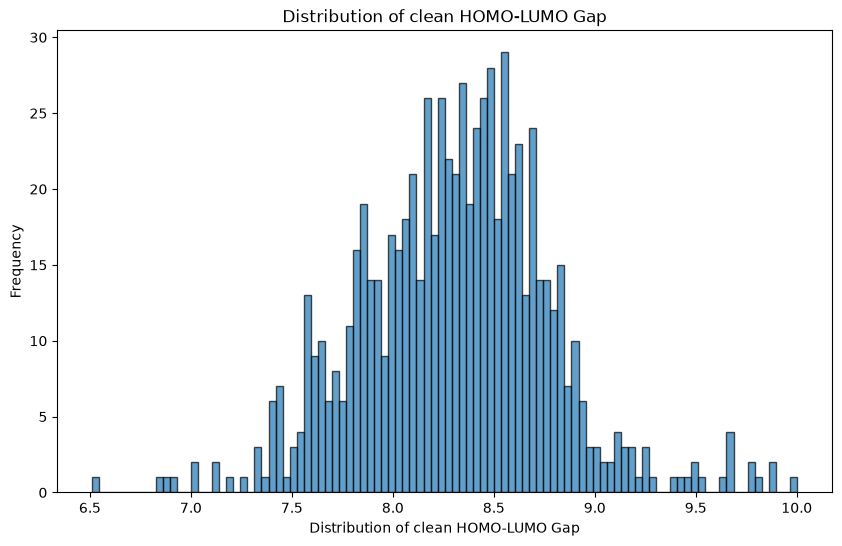

/var/folders/fv/9zptgcbd3591y8n1d18yqnlw0000gn/T/ipykernel_91638/2435802639.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(train_target_df, vert=False)


Text(0.5, 0, 'Distribution of clean HOMO-LUMO Gap')

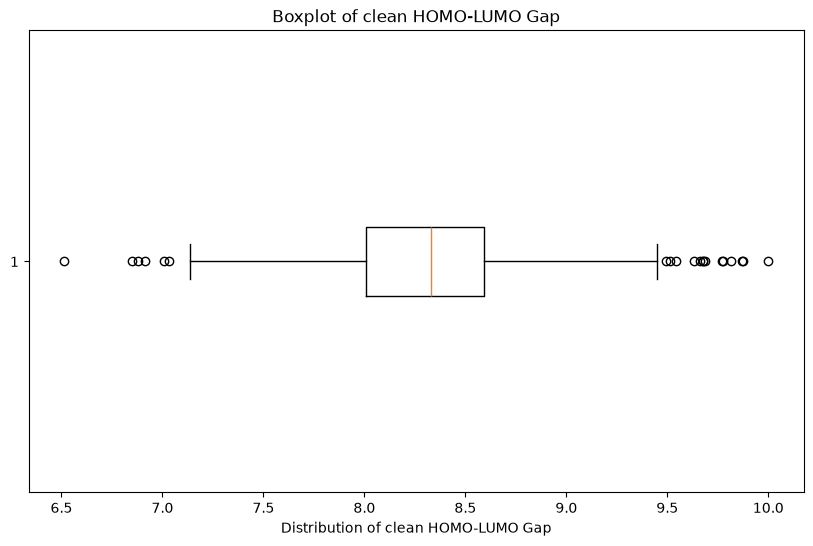

In [73]:
print(train_target_df.describe())
plt.figure(figsize=(10, 6))
plt.title('Distribution of clean HOMO-LUMO Gap')
plt.hist(train_target_df, alpha=0.7, bins=100, edgecolor='black')
plt.xlabel('Distribution of clean HOMO-LUMO Gap')
plt.ylabel('Frequency')
plt.show()

plt.figure(figsize=(10, 6))
plt.title('Boxplot of clean HOMO-LUMO Gap')
plt.boxplot(train_target_df, vert=False)
plt.xlabel('Distribution of clean HOMO-LUMO Gap')

count    186.000000
mean       8.311601
std        0.523014
min        4.468900
25%        8.088800
50%        8.364100
75%        8.638600
max        9.694100
Name: HOMO_LUMO_Gap_eV, dtype: float64


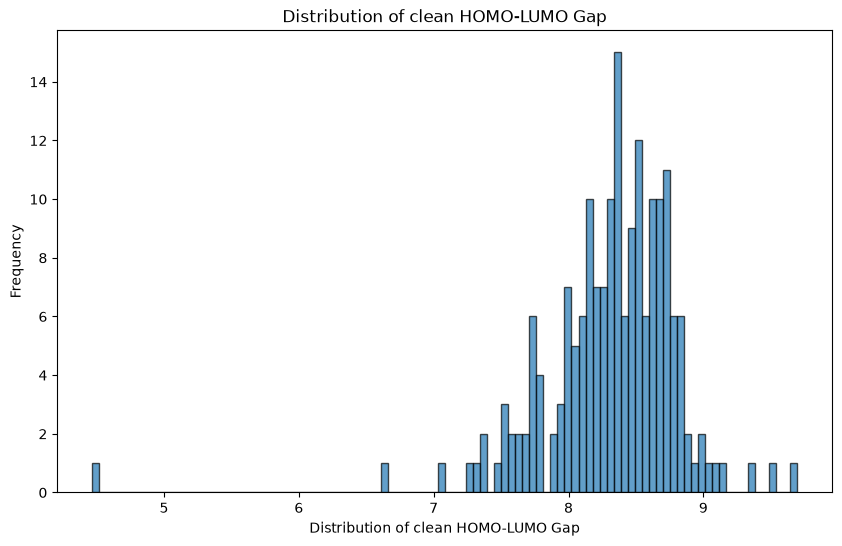

/var/folders/fv/9zptgcbd3591y8n1d18yqnlw0000gn/T/ipykernel_91638/962872785.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(test_target_df, vert=False)


Text(0.5, 0, 'Distribution of clean HOMO-LUMO Gap')

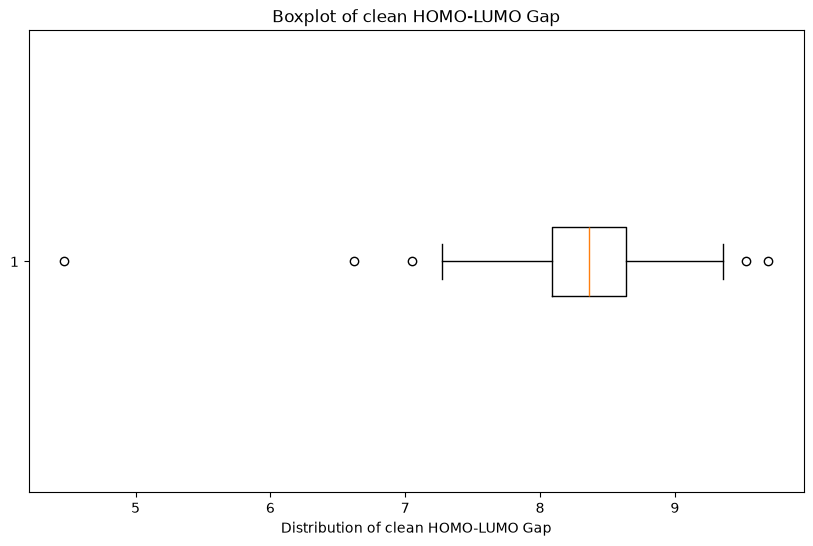

In [74]:
print(test_target_df.describe())
plt.figure(figsize=(10, 6))
plt.title('Distribution of clean HOMO-LUMO Gap')
plt.hist(test_target_df, alpha=0.7, bins=100, edgecolor='black')
plt.xlabel('Distribution of clean HOMO-LUMO Gap')
plt.ylabel('Frequency')
plt.show()

plt.figure(figsize=(10, 6))
plt.title('Boxplot of clean HOMO-LUMO Gap')
plt.boxplot(test_target_df, vert=False)
plt.xlabel('Distribution of clean HOMO-LUMO Gap')

In [75]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

dummy_reg = DummyRegressor(strategy="mean")

dummy_reg.fit(
    train_predictors_df,
    train_target_df
)

dummy_reg_predict = dummy_reg.predict(test_predictors_df)
dummy_mae = mean_absolute_error(test_target_df, dummy_reg_predict)
dummy_mse = mean_squared_error(test_target_df, dummy_reg_predict)
dummy_r2 = r2_score(test_target_df,dummy_reg_predict)

print("Dummy Regression Results")
print("MAE:", dummy_mae)
print("MSE:", dummy_mse)
print("R²:", dummy_r2)

Dummy Regression Results
MAE: 0.3565410723626857
MSE: 0.2720919917079166
R²: -6.87091039739407e-05


### Comparison between test and target distribution
There are a few extreme values in the test data set and not in the target data set. This would affect the model as the model may be less effective when it comes to extreme values.

In [76]:
test_df

,id,Energy_Hatree,es,Isotropic_Polarizability_au,HOMO_eV,LUMO_eV,Inner_energy_correction_Hatree,Thermal_correction_to_Enthalpy_Hatree,Thermal_correction_to_Gibbs_Free_Energy_Hatree,Entropy_Hatree,Dipole_Debye,Gibbs_Free_Energy_Hatree,Enthalpy_Hatree,HOMO_LUMO_Gap_eV
346,347,-1354.575596,0.999265,287.99745,-8.3042,0.0615,0.445339,0.000944,0.362369,0.083915,7.547149,-1354.213227,-1354.129312,8.3657
648,649,-4002.060335,0.983311,310.28316,-8.7205,0.0338,0.420866,0.000944,0.335383,0.086428,4.913498,-4001.724952,-4001.638525,8.7543
34,35,-2088.794687,0.997851,276.48166,-8.9172,-0.1463,0.323673,0.000944,0.242296,0.082320,5.411825,-2088.552391,-2088.470070,8.7709
890,891,-1946.843189,0.993704,349.48183,-8.5526,-0.1033,0.551366,0.000944,0.460576,0.091734,11.284560,-1946.382613,-1946.290878,8.4493
314,315,-1366.997491,0.998837,282.52483,-7.9876,-0.2886,0.363094,0.000944,0.284887,0.079152,2.983780,-1366.712604,-1366.633453,7.6990
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
896,897,-2566.662609,0.738763,328.96356,-9.1607,-0.1500,0.524800,0.000944,0.426566,0.099178,10.371874,-2566.236043,-2566.136865,9.0107
971,972,-4074.700991,0.995309,351.23629,-8.5764,-0.8040,0.362738,0.000944,0.277542,0.086140,8.644121,-4074.423448,-4074.337309,7.7724
670,671,-1139.568677,0.997739,218.14079,-8.8789,-0.0570,0.347271,0.000944,0.272612,0.075603,6.617391,-1139.296065,-1139.220462,8.8219
912,913,-1172.687329,0.994552,223.05428,-7.9747,0.0928,0.331969,0.000944,0.258090,0.074824,5.263864,-1172.429240,-1172.354416,8.0675


# Establish dummy baseline

In [77]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

test_df['high_gap'] = (test_df['HOMO_LUMO_Gap_eV'] >= gap_threshold).astype(int)
test_gap_df = test_df['high_gap']

dummy_clf = DummyClassifier(strategy="prior")

dummy_clf.fit(train_predictors_df, train_gap_df)

dummy_clf_predict = dummy_clf.predict(test_predictors_df)

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

dummy_accuracy = accuracy_score(test_gap_df, dummy_clf_predict)

dummy_precision = precision_score(test_gap_df,dummy_clf_predict)

dummy_recall = recall_score(test_gap_df,dummy_clf_predict)

dummy_f1 = f1_score(test_gap_df,dummy_clf_predict)

print("Dummy Classification Results")
print("Accuracy:", dummy_accuracy)
print("Precision:", dummy_precision)
print("Recall:", dummy_recall)
print("F1:", dummy_f1)




Dummy Classification Results
Accuracy: 0.45161290322580644
Precision: 0.0
Recall: 0.0
F1: 0.0


/Users/evanlin/2026-summar-ai/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [78]:
test_df

,id,Energy_Hatree,es,Isotropic_Polarizability_au,HOMO_eV,LUMO_eV,Inner_energy_correction_Hatree,Thermal_correction_to_Enthalpy_Hatree,Thermal_correction_to_Gibbs_Free_Energy_Hatree,Entropy_Hatree,Dipole_Debye,Gibbs_Free_Energy_Hatree,Enthalpy_Hatree,HOMO_LUMO_Gap_eV,high_gap
346,347,-1354.575596,0.999265,287.99745,-8.3042,0.0615,0.445339,0.000944,0.362369,0.083915,7.547149,-1354.213227,-1354.129312,8.3657,1
648,649,-4002.060335,0.983311,310.28316,-8.7205,0.0338,0.420866,0.000944,0.335383,0.086428,4.913498,-4001.724952,-4001.638525,8.7543,1
34,35,-2088.794687,0.997851,276.48166,-8.9172,-0.1463,0.323673,0.000944,0.242296,0.082320,5.411825,-2088.552391,-2088.470070,8.7709,1
890,891,-1946.843189,0.993704,349.48183,-8.5526,-0.1033,0.551366,0.000944,0.460576,0.091734,11.284560,-1946.382613,-1946.290878,8.4493,1
314,315,-1366.997491,0.998837,282.52483,-7.9876,-0.2886,0.363094,0.000944,0.284887,0.079152,2.983780,-1366.712604,-1366.633453,7.6990,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
896,897,-2566.662609,0.738763,328.96356,-9.1607,-0.1500,0.524800,0.000944,0.426566,0.099178,10.371874,-2566.236043,-2566.136865,9.0107,1
971,972,-4074.700991,0.995309,351.23629,-8.5764,-0.8040,0.362738,0.000944,0.277542,0.086140,8.644121,-4074.423448,-4074.337309,7.7724,0
670,671,-1139.568677,0.997739,218.14079,-8.8789,-0.0570,0.347271,0.000944,0.272612,0.075603,6.617391,-1139.296065,-1139.220462,8.8219,1
912,913,-1172.687329,0.994552,223.05428,-7.9747,0.0928,0.331969,0.000944,0.258090,0.074824,5.263864,-1172.429240,-1172.354416,8.0675,0


In [79]:
train_target_df

241    7.8667
747    8.4095
634    8.5194
956    8.3966
496    8.1712
        ...  
113    8.5961
287    7.8519
928    8.6040
467    8.0884
109    8.6436
Name: HOMO_LUMO_Gap_eV, Length: 740, dtype: float64

### Beating the dummy
Beating the dummy baseline establishes that the model has learned useful predictive patterns from the input features and performs better than a simple strategy of predicting the training mean (regression) or the most common class (classification). However, it does not prove that the model is scientifically valid, that the relationships are causal, or that it will generalise to new polymer datasets outside the evaluated data.

# Fit the honest linear-regression baseline

In [80]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, mean_squared_error

linear_model = Pipeline([("scaler", StandardScaler()),("model", LinearRegression())])
kfold = KFold(n_splits=5, shuffle=True, random_state=seed)

linear_train_predictors_df = train_predictors_df.drop(columns=['high_gap'])
linear_train_target_df = train_target_df
linear_test_predictors_df = test_predictors_df
linear_test_target_df = test_target_df

cv_results = cross_validate(
    linear_model,
    linear_train_predictors_df,
    linear_train_target_df,
    cv=kfold,
    scoring={
        "MAE": make_scorer(mean_absolute_error),
        "MSE": make_scorer(mean_squared_error),
        "R²": make_scorer(r2_score)
    },
    return_train_score=True
)       

cv_results.keys()

dict_keys(['fit_time', 'score_time', 'test_MAE', 'train_MAE', 'test_MSE', 'train_MSE', 'test_R²', 'train_R²'])

In [81]:

print("R² Fold values:", cv_results["test_R²"])
print("R² mean:", cv_results["test_R²"].mean())
print("R² std:", cv_results["test_R²"].std())

test_rmse = np.sqrt(cv_results["test_MSE"])
print("RMSE Fold values:", test_rmse)
print("RMSE mean:", test_rmse.mean())
print("RMSE std:", test_rmse.std())

R² Fold values: [ 0.23565117  0.14310569  0.27535595 -0.06720321  0.23502009]
R² mean: 0.16438593950487418
R² std: 0.12366781341806012
RMSE Fold values: [0.42927767 0.38696655 0.36209663 0.53934339 0.41199479]
RMSE mean: 0.42593580427050526
RMSE std: 0.0610914797381465


In [82]:
linear_model.fit(linear_train_predictors_df, linear_train_target_df)
linear_model_predict = linear_model.predict(linear_train_predictors_df)
test_predictions = linear_model.predict(test_predictors_df)

In [83]:
train_r2 = r2_score(linear_train_target_df, linear_model_predict)
train_mae = mean_absolute_error(linear_train_target_df, linear_model_predict)
train_mse = mean_squared_error(linear_train_target_df, linear_model_predict)
train_rmse = np.sqrt(train_mse)

test_r2 = r2_score(linear_test_target_df, test_predictions)
test_mae = mean_absolute_error(linear_test_target_df, test_predictions)
test_mse = mean_squared_error(linear_test_target_df, test_predictions)
test_rmse = np.sqrt(test_mse)

linear_regression_results = pd.DataFrame({
    "Metric": ["R²", "MAE", "MSE", "RMSE"],
    "Train": [train_r2, train_mae, train_mse, train_rmse],
    "Test": [test_r2, test_mae, test_mse, test_rmse]
})
linear_regression_results

,Metric,Train,Test
0,R²,0.210472,0.249356
1,MAE,0.312205,0.301145
2,MSE,0.174670,0.204230
3,RMSE,0.417935,0.451918


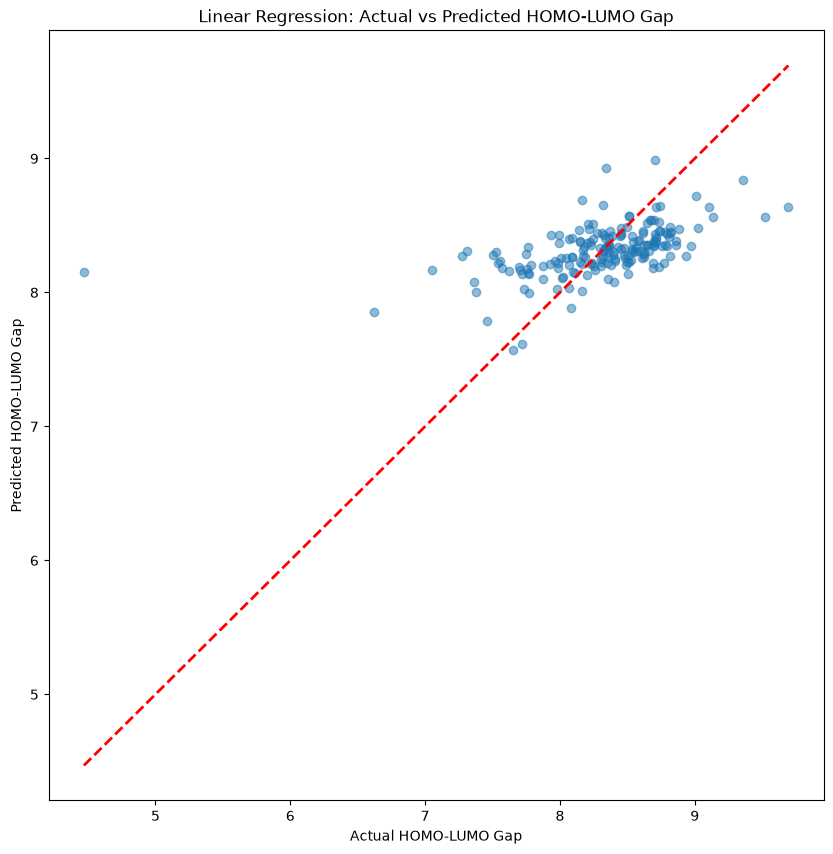

In [84]:
plt.figure(figsize=(10, 10))
plt.scatter(linear_test_target_df, test_predictions, alpha=0.5)
plt.plot([test_target_df.min(), test_target_df.max()], [test_target_df.min(), test_target_df.max()], 'r--', lw=2)
plt.title('Linear Regression: Actual vs Predicted HOMO-LUMO Gap')
plt.xlabel('Actual HOMO-LUMO Gap')
plt.ylabel('Predicted HOMO-LUMO Gap')
plt.show()


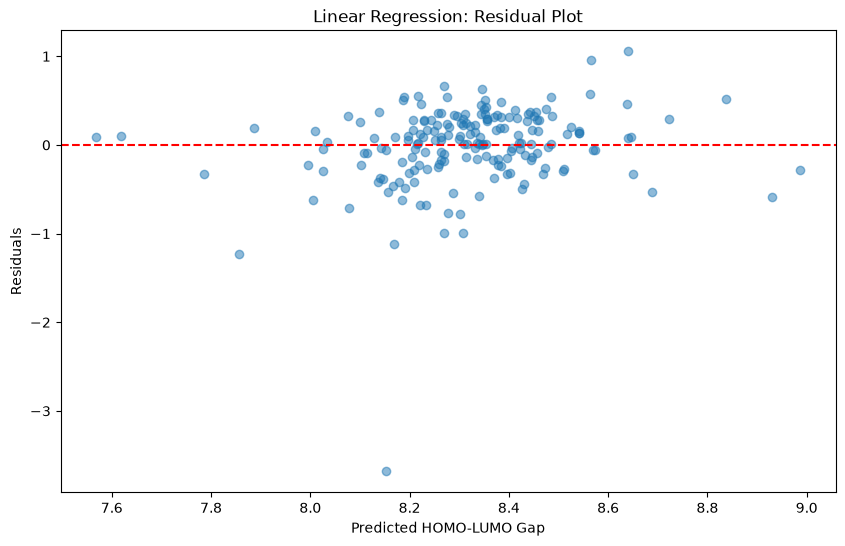

In [85]:
plt.figure(figsize=(10, 6))
residual_linear = linear_test_target_df - test_predictions
plt.scatter(test_predictions, residual_linear, alpha=0.5)
plt.xlabel('Predicted HOMO-LUMO Gap')
plt.ylabel('Residuals')
plt.title('Linear Regression: Residual Plot')
plt.axhline(y=0, color='r', linestyle='--')
plt.show()

In [86]:
top_5_errors = residual_linear.abs().nlargest(5)
top_5_errors

949    3.683522
488    1.233501
513    1.117818
773    1.054061
481    0.998043
Name: HOMO_LUMO_Gap_eV, dtype: float64

In [87]:
error_table = pd.DataFrame({
    "Actual": linear_test_target_df,
    "Predicted": test_predictions,
    "Residual": residual_linear,
    "absolute_error": abs(residual_linear)
})

top_5_error_table = error_table.sort_values(
    by="absolute_error",
    ascending=False
).head(5)

top_5_error_table

,Actual,Predicted,Residual,absolute_error
949,4.4689,8.152422,-3.683522,3.683522
488,6.6219,7.855401,-1.233501,1.233501
513,7.0510,8.168818,-1.117818,1.117818
773,9.6941,8.640039,1.054061,1.054061
481,7.3099,8.307943,-0.998043,0.998043


### Analysis

The MAE only differ around 0.01 while RMSE differs around 0.04. While the overal mean error is quite similar between train and test, showing a good fit for the model, rmse being significantly greater suggests that the model does not perform as well with extreme values. This is supported when extracting the top 5 greatest absolute errors, with all the values being extreme values. 

An overall low R2 (0.2) in both train and test shows that linear regression model only explain 20% of varaince within the data

Tying back to the comparison between target and test distribution, having extreme values only in the test data set, the result of it can be seen here as the model struggles with making acurate prediction with extreme values

# Run and diagnose the deliberate leakage experiment

In [88]:
gap_difference = (
    cleaned_df["LUMO_eV"] - cleaned_df["HOMO_eV"]
    - cleaned_df["HOMO_LUMO_Gap_eV"]
)

print(gap_difference.abs().max())

1.7763568394002505e-15


In [89]:
train_leaky_df = train_df.drop(columns=["HOMO_LUMO_Gap_eV", "id", 'high_gap'])
test_leaky_df = test_df.drop(columns=["HOMO_LUMO_Gap_eV", "id", 'high_gap'])
leaky_model = Pipeline([("scaler", StandardScaler()),("model", LinearRegression())])

leaky_model.fit(
    train_leaky_df,
    train_target_df
)

leaky_prediction = leaky_model.predict(test_leaky_df)

leaky_r2 = r2_score(test_target_df, leaky_prediction)
leaky_mae = mean_absolute_error(test_target_df, leaky_prediction)
leaky_mse = mean_squared_error(test_target_df, leaky_prediction)
leaky_rmse = np.sqrt(leaky_mse)

comparison = pd.DataFrame({
    "R²": [test_r2, leaky_r2],
    "MAE": [test_mae, leaky_mae],
    "MSE": [test_mse, leaky_mse],
    "RMSE": [test_rmse, leaky_rmse]
}, index=["Honest model", "Leaky model"])

comparison



,R²,MAE,MSE,RMSE
Honest model,0.249356,3.011451e-01,2.042301e-01,4.519182e-01
Leaky model,1.000000,2.158369e-15,5.216661e-30,2.284001e-15


### WHY IS THE LEAKY MODEL"S RESULTS INVALID?
Here, we can see the leaky model produced a set of perfect results with 0s accross all types of errors


The result is invalid because the model is the using the mathematical relationship between HOMO, LUMO and the GAP and not learning any new useful relationships. 

# Fit the honest logistic regression baseline

In [90]:
from sklearn.linear_model import LogisticRegression


logReg = Pipeline([("scaler", StandardScaler()),("model", LogisticRegression(max_iter=1000))])
logReg_fit = logReg.fit(linear_train_predictors_df, train_df['high_gap'])

In [91]:
linear_train_predictors_df

,Energy_Hatree,es,Isotropic_Polarizability_au,Inner_energy_correction_Hatree,Thermal_correction_to_Enthalpy_Hatree,Thermal_correction_to_Gibbs_Free_Energy_Hatree,Entropy_Hatree,Dipole_Debye,Gibbs_Free_Energy_Hatree,Enthalpy_Hatree
241,-4077.707023,0.998299,259.21871,0.268049,0.000944,0.195672,0.073321,3.443721,-4077.511351,-4077.438030
747,-4512.592808,0.952353,325.56736,0.427172,0.000944,0.335322,0.092794,3.781331,-4512.257487,-4512.164692
634,-3736.029205,0.998617,272.44516,0.365047,0.000944,0.285995,0.079996,5.632144,-3735.743210,-3735.663214
956,-1677.986904,0.999252,270.69900,0.329027,0.000944,0.252169,0.077802,6.161401,-1677.734734,-1677.656932
496,-1464.487651,0.996100,293.26548,0.403988,0.000944,0.321042,0.083891,8.297962,-1464.166609,-1464.082719
...,...,...,...,...,...,...,...,...,...,...
113,-1411.414562,0.990102,235.25380,0.371516,0.000944,0.290756,0.081704,4.180714,-1411.123806,-1411.042101
287,-2069.670952,0.930158,320.04579,0.458556,0.000944,0.361561,0.097939,5.600926,-2069.309391,-2069.211452
928,-1120.156310,0.998762,204.53946,0.306119,0.000944,0.235494,0.071569,4.145289,-1119.920816,-1119.849247
467,-2284.003552,0.990292,328.96052,0.376460,0.000944,0.291028,0.086376,6.523618,-2283.712524,-2283.626148


In [92]:
from sklearn.model_selection import StratifiedKFold

SKFold = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

In [93]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, mean_squared_error
cv_results_log = cross_validate(
    logReg,
    linear_train_predictors_df,
    train_df['high_gap'],
    cv=SKFold,
    scoring={
        "F1": "f1",
        "ROC_AUC": "roc_auc"
    },
    return_train_score=True
)
cv_results_log.keys()

dict_keys(['fit_time', 'score_time', 'test_F1', 'train_F1', 'test_ROC_AUC', 'train_ROC_AUC'])

In [94]:
print("F1 Fold values:", cv_results_log["test_F1"])
print("F1 mean:", cv_results_log["test_F1"].mean())
print("F1 std:", cv_results_log["test_F1"].std())

print("ROC_AUC Fold values:", cv_results_log["test_ROC_AUC"])
print("ROC_AUC mean:", cv_results_log["test_ROC_AUC"].mean())
print("ROC_AUC std:", cv_results_log["test_ROC_AUC"].std())

F1 Fold values: [0.73381295 0.77987421 0.76258993 0.69230769 0.69798658]
F1 mean: 0.7333142722046441
F1 std: 0.03451007534062081
ROC_AUC Fold values: [0.79948868 0.82176771 0.83783784 0.77684441 0.75310446]
ROC_AUC mean: 0.797808619430241
ROC_AUC std: 0.030388021844933694


In [95]:
logReg.fit(
    linear_train_predictors_df,
    train_df['high_gap']
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['Energy_Hatree','es','Isotropic_Polarizability_au',...,'Dipole_Debye', 'Gibbs_Free_Energy_Hatree','Enthalpy_Hatree']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [96]:
train_predictions = logReg.predict(
    linear_train_predictors_df,
)
test_predictions = logReg.predict(
    test_predictors_df
)

In [97]:
train_probability = logReg.predict_proba(linear_train_predictors_df)[:,1]
test_probability = logReg.predict_proba(test_predictors_df)[:,1]

In [98]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

train_accuracy = accuracy_score(train_df["high_gap"], train_predictions)
train_precision = precision_score(train_df["high_gap"], train_predictions)
train_recall = recall_score(train_df["high_gap"], train_predictions)
train_f1 = f1_score(train_df["high_gap"], train_predictions)
train_roc_auc = roc_auc_score(train_df["high_gap"], train_probability)

test_accuracy = accuracy_score(test_df["high_gap"], test_predictions)
test_precision = precision_score(test_df["high_gap"], test_predictions)
test_recall = recall_score(test_df["high_gap"], test_predictions)
test_f1 = f1_score(test_df["high_gap"], test_predictions)
test_roc_auc = roc_auc_score(test_df["high_gap"], test_probability)


classification_results = pd.DataFrame({
    "Accuracy": [train_accuracy, test_accuracy],
    "Precision": [train_precision, test_precision],
    "Recall": [train_recall, test_recall],
    "F1": [train_f1, test_f1],
    "ROC-AUC": [train_roc_auc, test_roc_auc]
}, index=["Training", "Test"])

classification_results

,Accuracy,Precision,Recall,F1,ROC-AUC
Training,0.740541,0.740541,0.740541,0.740541,0.806874
Test,0.720430,0.731481,0.774510,0.752381,0.780929


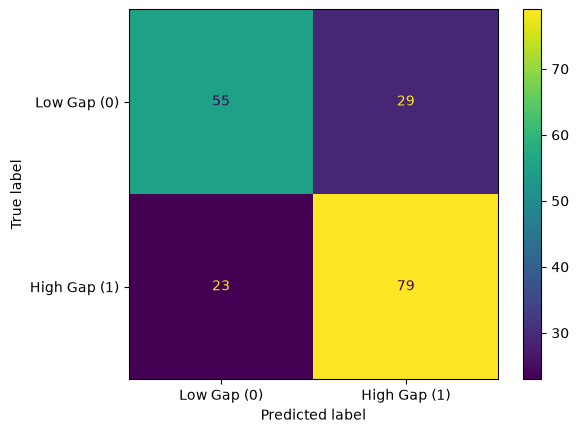

In [99]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as pl

ConfusionMatrixDisplay.from_predictions(
    test_df["high_gap"],
    test_predictions,
    display_labels=["Low Gap (0)", "High Gap (1)"]
)

In [100]:
value_information = pd.DataFrame({
    "id": test_df["id"],
    "true_gap": test_df["HOMO_LUMO_Gap_eV"],
    "true_class": test_df["high_gap"],
    "predicted_class": test_predictions,
    "predicted_probability": test_probability
})

false_positives = value_information[
    (value_information["true_class"] == 0) & (value_information["predicted_class"] == 1)
].head(2)

false_positives

,id,true_gap,true_class,predicted_class,predicted_probability
817,818,8.3100,0,1,0.787934
947,948,8.2185,0,1,0.833072


In [101]:
false_negatives = value_information[
    (value_information["true_class"] == 1) & (value_information["predicted_class"] == 0)
].head(2)

false_negatives

,id,true_gap,true_class,predicted_class,predicted_probability
34,35,8.7709,1,0,0.451738
890,891,8.4493,1,0,0.458064


### False positive and negative scientific cost

The importance of the model's performance depends on the relative cost of false positives and false negatives. If missing a truly high-gap polymer (a false negative) causes promising materials to be overlooked, then recall becomes more important than overall accuracy. On the other hand, if incorrectly identifying a low-gap polymer as high-gap (a false positive) leads to unnecessary experimental time and cost, then precision becomes the more important metric. Therefore, the preferred model depends on which type of error has the greater scientific consequence.

# Compare generalization evidence

In [102]:
regression_summary = pd.DataFrame({
    "Model": [
        "Dummy",
        "Linear Regression (Train)",
        "Linear Regression (CV Mean)",
        "Linear Regression (Test)",
        "Leaky Regression (Test)"
    ],
    "R²": [
        dummy_r2,
        train_r2,
        cv_results["test_R²"].mean(),
        test_r2,
        leaky_r2
    ],
    "MAE": [
        dummy_mae,
        train_mae,
        np.nan,
        test_mae,
        leaky_mae
    ],
    "RMSE": [
        np.sqrt(dummy_mse),
        train_rmse,
        np.sqrt(cv_results["test_MSE"]).mean(),
        test_rmse,
        leaky_rmse
    ]
})

regression_summary

,Model,R²,MAE,RMSE
0,Dummy,-0.000069,3.565411e-01,5.216244e-01
1,Linear Regression (Train),0.210472,3.122046e-01,4.179354e-01
2,Linear Regression (CV Mean),0.164386,NaN,4.259358e-01
3,Linear Regression (Test),0.249356,3.011451e-01,4.519182e-01
4,Leaky Regression (Test),1.000000,2.158369e-15,2.284001e-15


In [103]:
cv_summary = pd.DataFrame({
    "Metric":["R²", "RMSE"],
    "Fold values":[
        cv_results["test_R²"],
        np.sqrt(cv_results["test_MSE"])
    ],
    "Mean":[
        cv_results["test_R²"].mean(),
        np.sqrt(cv_results["test_MSE"]).mean()
    ],
    "Std": [
        cv_results["test_R²"].std(),
        np.sqrt(cv_results["test_MSE"]).std()
    ]
})
cv_summary

,Metric,Fold values,Mean,Std
0,R²,"[0.23565116755959215, 0.14310569493468206, 0.2...",0.164386,0.123668
1,RMSE,"[0.42927767202766215, 0.3869665454349925, 0.36...",0.425936,0.061091


In [104]:
classification_summary = pd.DataFrame({
    "Model":[
        "Dummy",
        "Train logistic",
        "CV mean logistics",
        "Test logistic"
    ],
    "Accuracy": [
        dummy_accuracy,
        train_accuracy,
        np.nan,
        test_accuracy
    ],
    "Precision":[
        dummy_precision,
        train_precision,
        np.nan,
        test_precision
    ],
    "Recall":[
        dummy_recall,
        train_recall,
        np.nan,
        test_recall
    ],
    "F1":[
        dummy_f1,
        train_f1,
        cv_results_log["test_F1"].mean(),
        test_f1
    ],
    "ROC-AUC":[
        np.nan,
        train_roc_auc,
        cv_results_log["test_ROC_AUC"].mean(),
        test_roc_auc
    ]
})

classification_summary

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Dummy,0.451613,0.000000,0.000000,0.000000,NaN
1,Train logistic,0.740541,0.740541,0.740541,0.740541,0.806874
2,CV mean logistics,NaN,NaN,NaN,0.733314,0.797809
3,Test logistic,0.720430,0.731481,0.774510,0.752381,0.780929


In [105]:
print("Classifcation threshold:", gap_threshold)
print("\nTraining class balance")
print(train_df["high_gap"].value_counts())

print("\nTest class balance")
print(test_df["high_gap"].value_counts())

Classifcation threshold: 8.33225

Training class balance
high_gap
0    370
1    370
Name: count, dtype: int64

Test class balance
high_gap
1    102
0     84
Name: count, dtype: int64


### Discussing data
There is suggestion of underfitting as the R2 data for both train and test is very low. This is also portrayed on the graph where the data points do not lie close to the linear line.

There is variability across the CV folds.

The one negatives fold as decreases the R2 value significanlty and should have under isolated investigation. There are alos a few large errors taht incerase the mse value, therefore the comparison between mae and mse is valuable. 

Training, cross-validation, and test results provide evidence about generalization to similar data, but cannot prove performance on future chemical space, especially for new chemical families not represented in the dataset.



# Critical questions
### Question 1

1. The target is the thing we want ai to be able to find a relationship for prediction and one row presents all the variables/value that are associated with the specific target value. In our case the target is  the HOMO-LUMO gap and one row contain all the calculate properties of the polymer. 

2. The predictors.

13. High/low classification only has scientific meaning if there is a reason for seperating polymers with gap energy above and below the mean. If not, this classification is created just for practice. 

14. calculation-to-calculation model as all structural information is not included in the predicotrs, only numerical variables. (train_predictors_df)



### Question 2


1. The final test set remain unused until the end is to ensure the remove of any bias and develop any relationships that the model would be able to use to derroive their prediction. The goal is for the model to learn and make predictions from raw/completely unseen data.

22. Having scaling in the pipeline allows all data to be standardised before it enters the model and alos prevents data leakage as scaling beforehand would influence the calculation between folds. (fold value table)

23. The target value can be directly calculated from HOMO and LUMO causing data leakage.

24. A random row split represent the information for the data as the splits are random and unbias. It does not necessarily estimate performance on genuinely new chemical families, because chemically related polymers may appear in both the training and test sets.

25. In general, the model does beat the dummy baseline, achieving higher R2 values and lower error value with higher accurary, recall etc.. values. However, they are not stable across all folds with negative values suggesting that some fold have worse predictions than the dummu prediction. 

26. The similarly low training and cross-validation R² values are consistent with underfitting or limited fit by the linear model, but do not prove high bias. There are high errors particularily with extreme values. There is also variance as the fold values ranges to negative values. This does not prove that the model is bad, as other facotrs have to also be taken into account. For examples, I suspected the random split for train and test dataset might play a part in the model not being able to accurately predict extreme values as all the extreme values are present in the test set which is unseen by the model. 

### Question 3

1. MAE and RMSE give different impressions as RMSE penalises large residuals more than MAE, while MAE weights errors proportionally. Both MAE and RMSE have the same units as the target, eV, while MSE has units of eV² 

32. A negative R2 means that the predicted values are worse/ greater errors than those you are comparing with (dummy)

33. False positive is when a low gap is wrongly determine to be high gap and vice verse for false negative. Determining which error matters more requires an assumption about the scientific application and the relative cost of missing a true high-gap polymer versus incorrectly selecting a low-gap polymer. Since the median threshold is primarily a practice classification boundary, the dataset alone does not establish these costs, hence neither one has more importance over the other. 

34. All of these calculation can disagree as they are measuring different things. Accuracy measure proprtional of right predictions, precision measures the proportion of predicted positives that are right, recall measures the propertions of raw positives that are right and F1 takes these presicion and recall into account, while ROC-AUC easures how well the model ranks or separates the two classes across classification thresholds. (classification summary table)

35. No. Linear regression minimizes squared errors during training, whereas MAE measures the average absolute prediction error in eV.